# Explaining each split of a malware clustering

Companion notebook to the paper. It clusters EMBER2024 Win32 malware and explains each split, from k to k + 1 groups, with readable traits not used for the clustering: capa capabilities, imported DLLs, section names, header flags. A split is explained when some trait's cautious difference between the two parts is at least τ = 0.30.

**You need** `subsets.json` (Colab asks you to upload it) and about 3 GB of free disk. The first run downloads EMBER2024's Win32 test file (2.6 GB) once.

EMBER2024 holds features and labels only, no executable files. Family labels are used only to check the explanations, never to make them.

## Settings

`SUBSET` picks one of three subsets of EMBER2024's Win32 test malware, all with a family label confidence of at least 0.8:

- **balanced_capa** (the paper's results): 6,287 files from 110 families, up to 100 per family from families with at least 20 files, all with capa results.
- **natural_capa**: 10,000 files at random among those with capa results, from 318 families, keeping the real family skew.
- **balanced_nocapa**: 6,753 files from 117 families, like balanced_capa but without requiring capa results.

In [1]:
#@title Settings
# Settings you can change: which subset, where the data comes from, which clustering methods, and the
# size of the checks.

SUBSET = "balanced_capa"        # "balanced_capa" (main), "natural_capa" or "balanced_nocapa"
SUBSETS_FILE = "subsets.json"   # the files of each subset by sha256
EMBER_ZIP = None                # path to EMBER2024's Win32_test.zip if you have it; None = download
METHODS = ["ward", "kmeans", "bisecting"]
KMEANS_DEPTH = 30               # k-means refits for every k, so it is explained to this many groups
SHOW_K = 30                     # groups shown at the bottom of the tree chart
SHUFFLES = 100                  # shuffles of every split in the shuffle test
STABILITY_SUBSAMPLES = 20       # resamples of each split's files in the stability check
DEPTH = 300                     # explain every split down to this many groups (the range searched in Table 1);
                                # None: stop after STOP_AFTER_UNEXPLAINED unexplained splits in a row instead
                                # (a run then takes about 6 minutes instead of 8)
STOP_AFTER_UNEXPLAINED = 10     # used only when DEPTH is None

In [3]:
#@title Install and load the libraries {display-mode: "form"}
# Installs fastcluster if it is missing and loads the libraries

import importlib.util, subprocess, sys
if importlib.util.find_spec("fastcluster") is None:   # the only library Colab doesn't preinstall
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "fastcluster"], check=True)

import hashlib, json, os, re, time, urllib.request, zipfile
from collections import Counter, defaultdict

import fastcluster
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import Markdown, display
from scipy.cluster.hierarchy import dendrogram, fcluster
from scipy.stats import norm
from sklearn.cluster import BisectingKMeans, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, completeness_score,
                             homogeneity_score, silhouette_score)
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_colwidth", None)
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scipy {scipy.__version__} | scikit-learn {sklearn.__version__} | fastcluster {fastcluster.__version__}")

Python 3.12.4 | numpy 2.5.4 | pandas 3.0.6 | scipy 1.18.1 | scikit-learn 1.9.1 | fastcluster 1.3.0


In [4]:
# The method's fixed settings: the random seed (every run gives the same result), the threshold τ
# (MIN_CONTRAST), the 5 % error level, how many reasons to show, and where the explanations stop.

SEED = 42

PCA_COMPONENTS = 50

CEILING_FILES = 10

MIN_TRAIT_PREVALENCE = 0.01

MIN_CONTRAST = 0.30  # τ

ALPHA = 0.05

TOP_TRAITS = 3

HEADLINE_REASONS = 2

SAME_REASON_JACCARD = 0.8

BREAK_AWAY = 0.25

NARRATIVE_CHANGES = 10

THRESHOLDS = (0.20, 0.25, 0.30, 0.35, 0.40, 0.50)

## Load the data

Builds the chosen subset from the EMBER2024 release, using the sample list in `subsets.json`.

In [5]:
# Builds the subset from the official EMBER2024 release: downloads Win32_test.zip once from Hugging
# Face, warns if it isn't byte for byte the release the paper used, and keeps the files listed in
# subsets.json, in the same order. The table is saved next to the notebook, so later runs load it
# in seconds.

# subsets.json next to the notebook; on Colab, asks you to upload it if it isn't there.
def find_subsets_file():
    if os.path.exists(SUBSETS_FILE):
        return SUBSETS_FILE
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f"Put {SUBSETS_FILE} next to this notebook.")
    print(f"Upload {SUBSETS_FILE}:")
    uploaded = files.upload()
    return next(name for name in uploaded if name.endswith(".json"))


# The release file: EMBER_ZIP if given, otherwise downloaded once; checked against the paper's sha256.
def ember_zip(source):
    path = EMBER_ZIP or source["file"]
    if not os.path.exists(path):
        print(f"Downloading {source['file']} ({source['size'] / 1e9:.1f} GB) from Hugging Face, once...")
        step = [0]

        def progress(blocks, block_size, total):
            done = min(blocks * block_size / total, 1.0)
            if done >= step[0] / 10:
                print(f"  {done:.0%}", end="", flush=True)
                step[0] += 1

        urllib.request.urlretrieve(source["url"], path + ".part", progress)
        os.replace(path + ".part", path)
        print()
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 24), b""):
            digest.update(block)
    if digest.hexdigest() != source["sha256"]:
        print(f"Warning: {path} is not the EMBER2024 release the paper used (its sha256 differs), "
              "so the results may differ from the paper's.")
    return path


SHA256_FIELD = re.compile(rb'"sha256": ?"([0-9a-f]{64})"')


# Every record of a wanted file, in the release's order; other lines are skipped without parsing them.
def records(path, wanted):
    with zipfile.ZipFile(path) as zf:
        for name in sorted(n for n in zf.namelist() if n.endswith(".jsonl")):
            with zf.open(name) as f:
                for i, line in enumerate(f):
                    m = SHA256_FIELD.search(line, 0, 400)
                    if m and m.group(1).decode() not in wanted:
                        continue
                    rec = json.loads(line)
                    if rec.get("sha256") in wanted:
                        yield name, i, rec


# The readable traits of a record: the explanation vocabulary, never used to cluster.
def readable(rec):
    imports = rec.get("imports") or {}
    section = rec.get("section") or {}
    header = rec.get("header") or {}
    coff, optional = header.get("coff") or {}, header.get("optional") or {}
    return {
        "capa": sorted({c.get("Capability") for c in rec.get("caps") or [] if c.get("Capability")}),
        "mbc": sorted({f"{m.get('Objective')}: {m.get('Behavior')}" for m in rec.get("mbc") or []}),
        "attack": sorted({f"{t.get('Tactic')}: {t.get('Technique')}" for t in rec.get("ttps") or []}),
        "behavior_tags": sorted(rec.get("behavior") or []),
        "packer_tags": sorted(rec.get("packer") or []),
        "property_tags": sorted(rec.get("file_property") or []),
        "group_tags": sorted(rec.get("group") or []),
        "exploit_tags": sorted(rec.get("exploit") or []),
        "import_dlls": sorted({d.lower() for d in imports}),
        "import_functions": sorted({f"{d.lower()}!{fn}" for d, fns in imports.items() for fn in (fns or [])
                                    if isinstance(fn, str)}),
        "section_names": sorted({s.get("name") for s in section.get("sections") or [] if s.get("name") is not None}),
        "entry_section": section.get("entry"),
        "coff_characteristics": sorted(coff.get("characteristics") or []),
        "subsystem": optional.get("subsystem"),
        "dll_characteristics": sorted(optional.get("dll_characteristics") or []),
    }


# The byte statistics of a record: what the clustering sees.
def unreadable(rec):
    row = {}
    for i, v in enumerate(rec.get("histogram") or []):
        row[f"hist_{i:03d}"] = v
    for i, v in enumerate(rec.get("byteentropy") or []):
        row[f"byteent_{i:03d}"] = v
    for k, v in (rec.get("strings") or {}).items():
        if isinstance(v, (int, float)):
            row[f"str_{k}"] = v
        elif k == "printabledist" and isinstance(v, list):
            for i, x in enumerate(v):
                row[f"printabledist_{i:02d}"] = x
    return row


# One row per listed file, in the listed order. The release lists every file twice, identical except
# for capa's results, which are in at most one copy: the copy with capa results is kept.
def build_subset(path, hashes):
    wanted, best = set(hashes), {}
    for name, i, rec in records(path, wanted):
        if rec.get("label") != 1:
            continue
        sha, has_capa = rec["sha256"], bool(rec.get("caps"))
        if sha not in best or (has_capa and not best[sha][0]):
            best[sha] = (has_capa, {"source_file": name, "source_line": i, "sha256": sha,
                                    "family": rec.get("family"), "family_confidence": rec.get("family_confidence"),
                                    "first_submission_date": rec.get("first_submission_date"),
                                    "detection_ratio": rec.get("detection_ratio"),
                                    **readable(rec), **unreadable(rec)})
    missing = wanted - set(best)
    if missing:
        raise ValueError(f"{len(missing)} listed files are not in the release, e.g. {sorted(missing)[0]}")
    return pd.DataFrame([best[h][1] for h in hashes])


with open(find_subsets_file(), encoding="utf-8") as f:
    spec = json.load(f)
hashes = spec["subsets"][SUBSET]["sha256"]
cache = f"{SUBSET}.parquet"
if not (os.path.exists(cache) and pd.read_parquet(cache, columns=["sha256"])["sha256"].tolist() == hashes):
    t0 = time.time()
    build_subset(ember_zip(spec["source"]), hashes).to_parquet(cache, index=False)
    print(f"Built {cache} from EMBER2024 in {time.time() - t0:.0f} s.")
df = pd.read_parquet(cache)
print(f"{len(df)} files, {df['family'].nunique()} families")

6287 files, 110 families


## Clustering space and readable traits

ATT&CK and MBC entries with a dotted ID (e.g. T1027.005) are sub-techniques: EMBER2024 stores them under their parent's name, so only the ID tells them apart.

In [6]:
# Which columns explain, and what kind of trait each is

READABLE = {
    "capa": "capability",
    "mbc": "behaviour",
    "attack": "ATT&CK",
    "behavior_tags": "tag",
    "packer_tags": "packer",
    "import_dlls": "imports",
    "section_names": "section",
    "coff_characteristics": "COFF",
    "dll_characteristics": "DLL char.",
}


NAME_PRIORITY = list(READABLE.values())


HEADER_FLAGS = {
    "32BIT_MACHINE": "32-bit machine", "BYTES_REVERSED_HI": "byte order reversed (high)",
    "BYTES_REVERSED_LO": "byte order reversed (low)", "DEBUG_STRIPPED": "debug information stripped",
    "DLL": "is a DLL", "EXECUTABLE_IMAGE": "executable image", "LARGE_ADDRESS_AWARE": "large-address aware",
    "LINE_NUMS_STRIPPED": "line numbers stripped", "LOCAL_SYMS_STRIPPED": "local symbols stripped",
    "RELOCS_STRIPPED": "relocations stripped", "DYNAMIC_BASE": "ASLR enabled", "NX_COMPAT": "DEP enabled",
    "NO_SEH": "no structured exception handling", "NO_ISOLATION": "no isolation",
    "TERMINAL_SERVER_AWARE": "terminal-server aware",
}



In [7]:


# PCA: the 50 numbers per file the clustering sees.
def clustering_space(df):
    hist = df[[c for c in df.columns if c.startswith("hist_")]].to_numpy(float)
    ent = df[[c for c in df.columns if c.startswith("byteent_")]].to_numpy(float)
    strs = df[[c for c in df.columns if c.startswith(("str_", "printabledist_"))]].to_numpy(float)
    hist = hist / np.clip(hist.sum(axis=1, keepdims=True), 1, None)
    ent = ent / np.clip(ent.sum(axis=1, keepdims=True), 1, None)
    strs = np.log1p(np.clip(strs, 0, None))
    X = StandardScaler().fit_transform(np.hstack([hist, ent, strs]))
    pca = PCA(n_components=PCA_COMPONENTS, random_state=SEED).fit(X)
    return pca.transform(X), float(pca.explained_variance_ratio_.sum())


# One yes/no column per readable trait present in at least 1 % of the files.
def readable_matrix(df):
    names, cols = [], []
    for col, label in READABLE.items():
        values = [set(items) if items is not None else set() for items in df[col]]   # missing = no traits
        counts = Counter(x for items in values for x in items)
        for item, c in sorted(counts.items()):
            if c / len(df) >= MIN_TRAIT_PREVALENCE:
                names.append(f"{label}: {item}")
                cols.append(np.array([item in items for items in values]))
    return np.column_stack(cols).astype(float), names


# The MBC / ATT&CK ID at the end of a trait name, e.g. 'T1055.012'.
def code_of(name):
    m = re.search(r"\[([^\]]+)\]$", name)
    return m.group(1) if m else None


# A readable name for a trait, e.g. 'Imports kernel32.dll' or 'Header flag: ASLR enabled'.
def display_name(name):
    kind, item = name.split(": ", 1)
    if kind == "capability":
        m = re.fullmatch(r"\(internal\) (.+) file limitation", item)
        if m:
            what = {"packer": "Packed", "visual basic": "Visual Basic program",
                    "installer": "Installer"}.get(m.group(1), m.group(1).capitalize() + " file")
            return f"{what}: capa couldn't analyse its code"
        return item[0].upper() + item[1:]
    if kind in ("behaviour", "ATT&CK"):              # "OBJECTIVE: Behaviour [ID]" -> "Behaviour (ID)"
        text = item.split(": ", 1)[-1]
        code = code_of(text)
        return re.sub(r"\s*\[[^\]]+\]$", "", text) + (f" ({code})" if code else "")
    if kind == "tag":
        return f"AV label: {item}"
    if kind == "packer":
        return f"AV label: packed with {item}"
    if kind == "imports":
        return f"Imports {item}"
    if kind == "section":
        if not item.strip(" \x00"):
            return f'Section with a blank name ("{item.replace(" ", "␣").replace(chr(0), "␀")}")'
        return f'Section "{item.replace(" ", "␣").replace(chr(0), "␀")}"'
    if kind in ("COFF", "DLL char."):
        return f"Header flag: {HEADER_FLAGS.get(item, item.lower().replace('_', ' '))}"
    return name


SAME_RULE, TOGETHER = "same capa rule", "always together"


# Why traits mark the same files: one capa rule with its own labels, or only always together here.
def relation(group):
    kinds = [n.split(": ", 1)[0] for n in group]
    if kinds[0] == "capability" and kinds.count("capability") == 1 and \
            all(k in ("behaviour", "ATT&CK") for k in kinds[1:]):
        return SAME_RULE
    return TOGETHER


# Traits that mark exactly the same files become one column, named by their relation.
def merge_identical(R, names):
    groups = defaultdict(list)
    for i, n in enumerate(names):
        groups[R[:, i].tobytes()].append(i)
    cols, labels, members, equivalents = [], [], [], {}
    for idx in sorted(groups.values()):
        idx = sorted(idx, key=lambda i: (NAME_PRIORITY.index(names[i].split(": ", 1)[0]), names[i]))
        group = [names[i] for i in idx]
        head = display_name(names[idx[0]])
        together = []
        if len(idx) > 1 and relation(group) == SAME_RULE:
            extra = [code_of(names[i]) or display_name(names[i]) for i in idx[1:]]
            extra = [e for e in extra if e not in head]
            if extra:
                head = head[:-1] + ", " + ", ".join(extra) + ")" if head.endswith(")") and code_of(names[idx[0]]) \
                    else head + " (" + ", ".join(extra) + ")"
        elif len(idx) > 1:
            together = [display_name(names[i]) for i in idx[1:]]
        base, copy = head, 2
        while head in labels:                          # two groups would be shown under the same name
            head, copy = f"{base} [{copy}]", copy + 1
        cols.append(R[:, idx[0]])
        labels.append(head)
        members.append(group)
        if len(idx) > 1:
            equivalents[head] = {"relation": relation(group), "members": group, "together": together}
    return np.column_stack(cols), labels, members, equivalents

In [8]:
# Builds both views for the data, and shows which traits are always together in it.

X, pca_variance = clustering_space(df)
R, names = readable_matrix(df)
Rm, labels, members, equivalents = merge_identical(R, names)
print(f"Clustering space: {X.shape[1]} numbers per file ({pca_variance:.0%} of the information in the raw features)")
same = [k for k, v in equivalents.items() if v["relation"] == SAME_RULE]
together = {k: v for k, v in equivalents.items() if v["relation"] == TOGETHER}
print(f"Readable traits: {len(names)}, {len(labels)} after merging the ones that mark exactly the same files: "
      f"{len(same)} capa rules shown with their MBC / ATT&CK IDs, and {len(together)} groups that are only always together.")
print("Examples of capa rules with their IDs:", "; ".join(same[:3]))
pd.DataFrame({"shown as": list(together), "always together in this data with": [", ".join(v["together"]) for v in together.values()]})

Clustering space: 50 numbers per file (66% of the information in the raw features)
Readable traits: 479, 367 after merging the ones that mark exactly the same files: 96 capa rules shown with their MBC / ATT&CK IDs, and 8 groups that are only always together.
Examples of capa rules with their IDs: Packed: capa couldn't analyse its code (T1027.002); Accept command line arguments (E1059); Allocate thread local storage (C0040)


,shown as,always together in this data with
0,Visual Basic program: capa couldn't analyse its code,Compiled from visual basic
1,Act as tcp client,"Connect tcp socket, Socket Communication (C0001.004), Socket Communication (C0001.008)"
2,Contain a thread local storage (.tls) section,"Section "".tls"""
3,Download and write a file,"Receive and write data from server to client, C2 Communication (B0030.003), Ingress Tool Transfer (T1105)"
4,Encrypt data using aes,Reference aes constants
5,Packed with mpress,"Section "".mpress2"""
6,Virtual Machine Detection (B0009.012),Virtualization/Sandbox Evasion (T1497.002)
7,Registry (C0036.003),Registry (C0036.004)


## Choosing the number of groups (Table 1)

Each method's number of groups for Ward's tree, between 2 and 300, and its ARI against the family labels, which no method sees. The paper's Table 1 shows six of these methods; prediction strength, the L-method and both gap statistic rules give the same picture (1, 3, 300 and 300 groups). Takes about 5 minutes.

In [9]:
# Builds Ward's tree
Z = fastcluster.linkage_vector(X, method="ward")

In [10]:
# The methods for choosing the number of groups (Table 1)

SILHOUETTE_SAMPLE = 2000
GAP_REFERENCES = 10


MOJENA_C = 1.25


DUDA_HART_Z = 3.20


PS_THRESHOLD = 0.8


PS_REPEATS = 5


# How spread out the groups are: squared distances of the files to their group's centre.
def within_dispersion(X, labels):
    total = 0.0
    for c in np.unique(labels):
        g = X[labels == c]
        total += float(((g - g.mean(axis=0)) ** 2).sum())
    return total


# Gap statistic: the real data's spread against random data clustered the same way.
def gap_statistic(Z, X, ks, rng):
    ks = [1] + list(ks)
    logw = np.array([np.log(within_dispersion(X, fcluster(Z, k, "maxclust")) if k > 1
                            else ((X - X.mean(axis=0)) ** 2).sum()) for k in ks])
    lo, hi = X.min(axis=0), X.max(axis=0)
    ref = np.empty((GAP_REFERENCES, len(ks)))
    for b in range(GAP_REFERENCES):
        R = rng.uniform(lo, hi, size=X.shape)
        Zr = fastcluster.linkage_vector(R, method="ward")
        ref[b] = [np.log(within_dispersion(R, fcluster(Zr, k, "maxclust")) if k > 1
                         else ((R - R.mean(axis=0)) ** 2).sum()) for k in ks]
    gap = ref.mean(axis=0) - logw
    s = ref.std(axis=0) * np.sqrt(1 + 1 / GAP_REFERENCES)
    chosen = next((ks[i] for i in range(len(ks) - 1) if gap[i] >= gap[i + 1] - s[i + 1]), ks[-1])
    return int(chosen), {int(k): (float(g), float(e)) for k, g, e in zip(ks, gap, s)}


# The k before the largest jump between consecutive merge heights.
def largest_jump(Z, ks):
    h = Z[:, 2]
    n = len(h) + 1
    jumps = {int(k): float(h[n - k] - h[n - k - 1]) for k in ks}
    return max(jumps, key=jumps.get), jumps


# The height of the merge that takes k groups down to k - 1.
def merge_heights_by_k(Z, ks):
    h, n = Z[:, 2], len(Z) + 1
    return {int(k): float(h[n - k]) for k in ks}


# L-method: the elbow of the merge-height curve, from two straight-line fits.
def l_method(xs, ys):
    xs, ys = np.asarray(xs, float), np.asarray(ys, float)
    cutoff = len(xs)
    last = None
    while True:
        x, y = xs[:cutoff], ys[:cutoff]
        best, knee = np.inf, None
        for c in range(2, len(x) - 1):
            err = 0.0
            for xx, yy in ((x[:c], y[:c]), (x[c:], y[c:])):
                coef = np.polyfit(xx, yy, 1)
                err += len(xx) / len(x) * np.sqrt(np.mean((np.polyval(coef, xx) - yy) ** 2))
            if err < best:
                best, knee = err, int(x[c - 1])
        if knee is None or knee == last or 2 * knee >= cutoff + xs[0]:
            return knee
        last = knee
        cutoff = max(5, int(np.searchsorted(xs, 2 * knee)) + 1)


# Mojena's rule: groups left before the first unusually high merge.
def mojena(Z, c=MOJENA_C):
    h = Z[:, 2]
    threshold = h.mean() + c * h.std(ddof=1)
    return int((h > threshold).sum() + 1), float(threshold)


# The split that goes from k to k + 1 groups in Ward's tree.
def split_at(Z, k):
    lo, hi = fcluster(Z, k, "maxclust"), fcluster(Z, k + 1, "maxclust")
    for c in np.unique(lo):
        children = np.unique(hi[lo == c])
        if len(children) == 2:
            return lo == c, hi == children[0], hi == children[1]
    raise RuntimeError(f"no split between {k} and {k + 1}")


# Duda-Hart rule: keep splitting while a split reduces the spread more than chance.
def duda_hart(Z, X, z=DUDA_HART_Z, max_k=200):
    p = X.shape[1]
    for k in range(1, max_k):
        parent, a, b = split_at(Z, k)
        je1 = within_dispersion(X[parent], np.zeros(int(parent.sum())))
        je2 = within_dispersion(X[a], np.zeros(int(a.sum()))) + within_dispersion(X[b], np.zeros(int(b.sum())))
        n = int(parent.sum())
        critical = 1 - 2 / (np.pi * p) - z * np.sqrt(2 * (1 - 8 / (np.pi ** 2 * p)) / (n * p))
        if je2 / je1 >= critical:
            return k
    return max_k


# Prediction strength: do two random halves' groupings predict each other?
def prediction_strength(X, ks, rng, repeats=PS_REPEATS):
    scores = {int(k): [] for k in ks}
    n = len(X)
    for _ in range(repeats):
        idx = rng.permutation(n)
        tr, te = X[idx[: n // 2]], X[idx[n // 2:]]
        Ztr, Zte = fastcluster.linkage_vector(tr, method="ward"), fastcluster.linkage_vector(te, method="ward")
        for k in ks:
            ltr, lte = fcluster(Ztr, k, "maxclust"), fcluster(Zte, k, "maxclust")
            centroids = np.stack([tr[ltr == c].mean(axis=0) for c in np.unique(ltr)])
            assigned = np.argmin(((te[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2), axis=1)
            worst = 1.0
            for c in np.unique(lte):
                members = assigned[lte == c]
                m = len(members)
                if m < 2:
                    continue
                counts = np.bincount(members)
                worst = min(worst, float((counts * (counts - 1)).sum() / (m * (m - 1))))
            scores[int(k)].append(worst)
    mean = {k: float(np.mean(v)) for k, v in scores.items()}
    ok = [k for k, v in mean.items() if v >= PS_THRESHOLD]
    return (max(ok) if ok else 1), mean


# Runs every method over 2-300 groups and returns each one's choice.
def criteria(X, fam):
    import fastcluster
    from scipy.cluster.hierarchy import fcluster
    from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                                 homogeneity_score, silhouette_score)
    n = len(X)
    k_range = range(2, max(3, min(301, n // 4 + 1)))
    Z = fastcluster.linkage_vector(X, method="ward")
    cuts = {k: fcluster(Z, k, "maxclust") for k in k_range}
    s = min(SILHOUETTE_SAMPLE, n)
    sil = {k: float(silhouette_score(X, cuts[k], sample_size=s, random_state=SEED)) for k in k_range}
    db = {k: float(davies_bouldin_score(X, cuts[k])) for k in k_range}
    ch = {k: float(calinski_harabasz_score(X, cuts[k])) for k in k_range}
    k_gap, gap_curve = gap_statistic(Z, X, k_range, np.random.default_rng(SEED))
    gap_only = {k: g for k, (g, _) in gap_curve.items() if k >= 2}
    heights = merge_heights_by_k(Z, k_range)
    k_ps, _ = prediction_strength(X, range(2, max(3, min(121, n // 10 + 1))), np.random.default_rng(SEED))
    chosen = {"silhouette (maximum, sampled)": max(sil, key=sil.get), "Davies-Bouldin (minimum)": min(db, key=db.get),
              "Calinski-Harabasz (maximum)": max(ch, key=ch.get), "gap statistic (1-SE rule)": k_gap,
              "gap statistic (maximum)": max(gap_only, key=gap_only.get),
              "largest jump in merge height": largest_jump(Z, k_range)[0],
              "L-method (merge heights)": l_method(list(heights), list(heights.values())),
              "Mojena (c = 1.25)": min(mojena(Z)[0], k_range.stop - 1), "Duda-Hart (z = 3.20)": duda_hart(Z, X, max_k=k_range.stop - 1),
              "prediction strength (>= 0.8)": k_ps}
    ari = {k: adjusted_rand_score(fam, cuts[k]) for k in k_range}
    best = max(ari, key=ari.get)
    n_fam = len(set(fam))
    at_fam = fcluster(Z, n_fam, "maxclust")
    return {"k_range": [k_range.start, k_range.stop - 1], "chosen": {k: int(v) for k, v in chosen.items()},
            "best_ari_k": int(best), "best_ari": float(ari[best]),
            "at_family_count": {"ari": adjusted_rand_score(fam, at_fam), "homogeneity": homogeneity_score(fam, at_fam)}}

In [11]:
# Asks every method for its number of groups on this data, and shows each choice with its ARI.

t0 = time.time()
rules = criteria(X, df["family"].to_numpy())
agree = {name: adjusted_rand_score(df["family"], fcluster(Z, k, "maxclust")) if k > 1 else 0.0
         for name, k in rules["chosen"].items()}
table = pd.DataFrame({"number of groups chosen": rules["chosen"],
                      "ARI": {n: round(a, 2) for n, a in agree.items()}})
table = table.sort_values("number of groups chosen")
print(f"{df['family'].nunique()} families in the data. Methods searched {rules['k_range'][0]}–{rules['k_range'][1]} groups "
      f"({time.time() - t0:.0f} s). The number of groups that agrees best with the families is {rules['best_ari_k']} "
      f"(ARI {rules['best_ari']:.2f}); none of the methods can know that.")
table

110 families in the data. Methods searched 2–300 groups (162 s). The number of groups that agrees best with the families is 268 (ARI 0.32); none of the methods can know that.


,number of groups chosen,ARI
prediction strength (>= 0.8),1,0.00
Calinski-Harabasz (maximum),2,0.01
largest jump in merge height,2,0.01
L-method (merge heights),3,0.01
Duda-Hart (z = 3.20),28,0.11
Mojena (c = 1.25),213,0.29
Davies-Bouldin (minimum),271,0.32
"silhouette (maximum, sampled)",300,0.31
gap statistic (maximum),300,0.31
gap statistic (1-SE rule),300,0.31


## Explaining the splits

Groups are named by a number and a path. At each split, the larger part keeps its number and adds 1 to its path; the smaller part takes number k + 1 and adds 2. For example, Group 7 (11112) was in the larger part of four splits and then broke away as the smaller part at split 6 → 7.

In [12]:
# How the groups at k and at k + 1 are compared, for any clustering method.

# The clustering into k groups, computed the first time it is needed.
class Partitions(dict):

    def __init__(self, X, method):
        super().__init__({1: np.zeros(len(X), dtype=int)})
        if method not in ("ward", "kmeans", "bisecting"):
            raise ValueError(method)
        self.X, self.method = X, method
        self.Z = fastcluster.linkage_vector(X, method="ward") if method == "ward" else None

    def __missing__(self, k):
        if self.method == "ward":
            self[k] = fcluster(self.Z, k, "maxclust")
        elif self.method == "kmeans":
            self[k] = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(self.X)
        else:
            self[k] = BisectingKMeans(n_clusters=k, random_state=SEED).fit_predict(self.X)
        return self[k]


# Starts the clustering for one method.
def partitions(X, method):
    return Partitions(X, method)


# What changes from k to k + 1 groups: the fast path for one clean split, otherwise the general one.
def transition(lo, hi):
    pairs = np.unique(np.stack([lo, hi], axis=1), axis=0)
    sources, counts = np.unique(pairs[:, 0], return_counts=True)
    if len(pairs) == len(np.unique(pairs[:, 1])) and (counts == 2).sum() == 1 and (counts <= 2).all():
        return split_transition(lo, hi, pairs, sources[counts == 2][0])
    return general_transition(lo, hi)


# Fast path: the one group that splits in two, and its two parts.
def split_transition(lo, hi, pairs, split):
    parent = lo == split
    hi_ids = np.unique(hi)
    row = np.zeros(len(hi_ids), dtype=int)            # the parent's row of the general crossing table
    for c in pairs[pairs[:, 0] == split, 1]:
        row[np.searchsorted(hi_ids, c)] = int(((hi == c) & parent).sum())
    order = np.argsort(-row)                           # the same order as the general transition's
    a, b = parent & (hi == hi_ids[order[0]]), parent & (hi == hi_ids[order[1]])
    return {"parent": parent, "a": a, "b": b, "cleanliness": 1.0, "coverage": 1.0, "changing_files": int(b.sum())}


# General case (k-means): crosses every group at k with every group at k + 1.
def general_transition(lo, hi):
    lo_ids, hi_ids = np.unique(lo), np.unique(hi)
    C = np.array([[np.sum((lo == i) & (hi == j)) for j in hi_ids] for i in lo_ids])
    main_source = C.argmax(axis=0)
    in_lineage = sum(C[main_source[j], j] for j in range(len(hi_ids)))
    p = int((C.sum(axis=1) - C.max(axis=1)).argmax())
    order = np.argsort(-C[p])
    parent = lo == lo_ids[p]
    a, b = parent & (hi == hi_ids[order[0]]), parent & (hi == hi_ids[order[1]])
    lo_pos, hi_pos = np.searchsorted(lo_ids, lo), np.searchsorted(hi_ids, hi)
    continues = (hi_pos == C.argmax(axis=1)[lo_pos]) & (main_source[hi_pos] == lo_pos)
    changing = ~continues
    coverage = float((changing & (a | b)).sum() / changing.sum()) if changing.any() else 1.0
    return {"parent": parent, "a": a, "b": b, "cleanliness": float(in_lineage / len(lo)),
            "coverage": coverage, "changing_files": int(changing.sum())}

In [13]:
# The cautious difference
def conservative_difference(pa, na, pb, nb, z):
    def wilson(p, n):
        den = 1 + z ** 2 / n
        centre = (p + z ** 2 / (2 * n)) / den
        half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
        return centre - half, centre + half
    la, ua = wilson(pa, na)
    lb, ub = wilson(pb, nb)
    d = pa - pb
    lower = d - np.sqrt((pa - la) ** 2 + (ub - pb) ** 2)
    upper = d + np.sqrt((ua - pa) ** 2 + (pb - lb) ** 2)
    return np.where(lower > 0, lower, np.where(upper < 0, -upper, 0.0))


# One split's verdict, its strongest traits and up to two different reasons.
def explain(Rm, labels, a, b, z):
    pa, pb = Rm[a].mean(axis=0), Rm[b].mean(axis=0)
    bound = conservative_difference(pa, a.sum(), pb, b.sum(), z)
    order = np.lexsort((-np.abs(pa - pb), -bound))      # ties broken by the raw difference
    item = lambda i: (labels[i], float(pa[i]), float(pb[i]), float(bound[i]))
    passing = [i for i in order if bound[i] >= MIN_CONTRAST]
    reasons, inside = [], a | b
    for i in passing:
        col = Rm[inside, i] > 0
        if all(((col & (Rm[inside, j] > 0)).sum() / max((col | (Rm[inside, j] > 0)).sum(), 1)) < SAME_REASON_JACCARD
               for j in reasons):
            reasons.append(i)
        if len(reasons) == HEADLINE_REASONS:
            break
    return {"traits": [item(i) for i in passing[:TOP_TRAITS]], "reasons": [item(i) for i in reasons],
            "closest": item(order[0]), "best": float(bound[order[0]])}


# Validation only: how different the families of the two parts are (total variation distance).
def family_tvd(fam, a, b):
    ca, cb = Counter(fam[a]), Counter(fam[b])
    na, nb = a.sum(), b.sum()
    return 0.5 * sum(abs(ca[f] / na - cb[f] / nb) for f in set(ca) | set(cb))


# Validation only: the most common families in a part.
def top_families(fam, mask, n=3):
    return Counter(fam[mask]).most_common(n)


# Numbers the groups 1..k and records each one's lineage path.
def number_groups(parts, rows):
    current = {int(parts[1][0]): (1, "")}
    for r in rows:
        k = r["k_from"]
        lo, hi = parts[k], parts[k + 1]
        pnum, ppath = current[int(lo[r["_parent"]][0])]
        ja, jb = int(hi[r["_a"]][0]), int(hi[r["_b"]][0])
        new = {ja: (pnum, ppath + "1"), jb: (k + 1, ppath + "2")}
        claims = defaultdict(list)
        for j in np.unique(hi):
            j = int(j)
            if j not in new:
                src = int(Counter(lo[hi == j]).most_common(1)[0][0])
                claims[current[src]].append(j)
        used = {v[0] for v in new.values()}
        free = iter(sorted(set(range(1, k + 2)) - used - {num for num, _ in claims}))
        for (num, path), js in claims.items():
            js = sorted(js, key=lambda j: -np.sum(hi == j))
            if num in used:
                js = [None] + js
            for i, j in enumerate(js):
                if j is not None:
                    new[j] = (num, path) if i == 0 else (next(free), path + "'")
            used.add(num)
        assert sorted(num for num, _ in new.values()) == list(range(1, k + 2)), f"numbers at k={k + 1}"
        r["_parent_label"] = group_label(pnum, ppath)
        r["_label_a"], r["_label_b"] = group_label(*new[ja]), group_label(*new[jb])
        r["_num_a"], r["_num_b"] = new[ja][0], new[jb][0]
        r["split"] = f"{r['_parent_label']} → {r['_label_a']} + {r['_label_b']}"
        current = new


# 'Group 7 (11211)'.
def group_label(num, path):
    return f"Group {num} ({path or 'all'})"


# 'Group 7 (11211)' -> 'Group 7'.
def short(label):
    return label.split(" (")[0]


# 'expiro 73, facido 59 (of 555)'.
def family_text(fams, size):
    return ", ".join(f"{f} {c}" for f, c in fams) + f" (of {size})"


# 'Split 22 -> 23: 119 files break away from Group 9'.
def headline(r):
    na, nb = r["sizes"]
    if nb / (na + nb) < BREAK_AWAY:
        what = f"{nb} files break away from {r['_parent_label']}"
    else:
        what = f"{r['_parent_label']} divides in two ({na} and {nb} files)"
    return f"Split {r['k_from']} → {r['k_to']}: {what}"


# One reason in words: its share in each part, with its marks.
def reason_text(trait, r):
    name, pa, pb, _ = trait
    a, b = short(r["_label_a"]), short(r["_label_b"])
    hi_g, hi_p, lo_g, lo_p = (a, pa, b, pb) if pa >= pb else (b, pb, a, pa)
    return f"**{name}**: {hi_p:.0%} of {hi_g} vs {lo_p:.0%} of {lo_g}" + together_mark(name, r)


# 'A, B and 3 more'.
def listed(names, most=2):
    return ", ".join(names[:most]) + (f" and {len(names) - most} more" if len(names) > most else "")


# The 'always together' note: traits that mark exactly the same files in the whole dataset.
def together_mark(name, r):
    together = r.get("together", {}).get(name)
    return f" · *always together in this data with {listed(together)}*" if together else ""


# Everything about one split, as an analyst reads it.
def split_block(r, details=True):
    a, b = short(r["_label_a"]), short(r["_label_b"])
    lines = [f"**{headline(r)}**", ""]
    if r["explained"]:
        lines += [f"- {reason_text(t, r)}" for t in r["reasons"]]
    else:
        lines += [f"- *No readable trait clearly separates them.* Closest: {reason_text(r['closest'], r)}."
                  if r["best"] > 0 else
                  f"- *No readable trait clearly separates them: with parts of {r['sizes'][0]} and {r['sizes'][1]} "
                  f"files, no difference is large enough to rule out chance.* Largest difference: "
                  f"{reason_text(r['closest'], r)}."]
    lines += [f"- Families: {a}: {family_text(r['families_a'], r['sizes'][0])}; "
              f"{b}: {family_text(r['families_b'], r['sizes'][1])}"]
    if r["coverage"] < 0.999:
        lines += [f"- *This split describes only {r['coverage']:.0%} of the {r['changing_files']} files "
                  f"that change between {r['k_from']} and {r['k_to']} groups.*"]
    if details:
        lines += ["", "<details><summary>Details</summary>", "",
                  f"- **Lineage:** {r['split']}",
                  f"- **Strongest traits.** Share of files with the trait in each part, then the *cautious "
                  f"difference*: how far apart the two shares are at least, according to Newcombe's interval with the "
                  f"Bonferroni correction. A split is explained when it is at least τ = {MIN_CONTRAST:.2f}."]
        for t, pa, pb, bd in r["traits"]:
            lines.append(f"  - {t}: {pa:.0%} of {a} vs {pb:.0%} of {b}; cautious difference {bd:.0%}")
            if r.get("together", {}).get(t):
                lines.append(f"    - always together in this data with: {', '.join(r['together'][t])}")
        if not r["traits"]:
            lines.append(f"  - none reaches τ = {MIN_CONTRAST:.2f}; the largest cautious difference is {r['best']:.2f}")
        lines += [f"- **Family separation** {r['family_tvd']:.2f}: total variation distance between the families of the "
                  f"two parts (1 = no family in common). Used only to check the method, never to explain.",
                  f"- **Coverage** {r['coverage']:.0%}: the share of the files that change between {r['k_from']} and "
                  f"{r['k_to']} groups that this split describes. **Cleanliness** {r['cleanliness']:.3f}: the share of "
                  f"files that stay in their group's line of descent (1 = one clean split).", "", "</details>"]
    return "\n".join(lines)


# How many splits are explained with another τ, and their family separation.
def sensitivity(rows, threshold):
    best, tvd = np.array([r["best"] for r in rows]), np.array([r["family_tvd"] for r in rows])
    ok = best >= threshold
    return {"threshold": threshold, "explained": int(ok.sum()),
            "tvd_explained": float(tvd[ok].mean()) if ok.any() else None,
            "tvd_unexplained": float(tvd[~ok].mean()) if (~ok).any() else None}


# Where the explanations stop: the last explained split before 10 unexplained in a row.
def dry_up(rows):
    last, streak = 1, 0
    for r in rows:
        if r["explained"]:
            last, streak = r["k_to"], 0
        else:
            streak += 1
            if streak >= STOP_AFTER_UNEXPLAINED:
                return last
    return None


# Runs everything for one method, split after split, until the explanations stop.
def analyse(df, method, depth=None):
    depth = depth or DEPTH
    fam = df["family"].to_numpy()
    X, pca_variance = clustering_space(df)
    R, names = readable_matrix(df)
    Rm, labels, members, equivalents = merge_identical(R, names)
    z = norm.isf(ALPHA / (2 * len(names)))     # every original trait still counts as a test
    parts = partitions(X, method)
    ceiling = max(2, len(df) // CEILING_FILES)
    last_k = min(depth, ceiling) if depth else ceiling
    rows, streak = [], 0
    for k in range(1, last_k):
        if not depth and streak >= STOP_AFTER_UNEXPLAINED:
            break
        t = transition(parts[k], parts[k + 1])
        a, b = t["a"], t["b"]
        e = explain(Rm, labels, a, b, z)
        shown = {x[0] for x in e["traits"]} | {x[0] for x in e["reasons"]} | {e["closest"][0]}
        e["together"] = {s: equivalents[s]["together"] for s in shown
                         if s in equivalents and equivalents[s]["together"]}
        rows.append({"k_from": k, "k_to": k + 1, "parent_size": int(t["parent"].sum()),
                     "sizes": [int(a.sum()), int(b.sum())], "cleanliness": t["cleanliness"],
                     "coverage": t["coverage"], "changing_files": t["changing_files"],
                     "explained": e["best"] >= MIN_CONTRAST, **e,
                     "family_tvd": float(family_tvd(fam, a, b)),
                     "families_a": top_families(fam, a), "families_b": top_families(fam, b),
                     "_parent": t["parent"], "_a": a, "_b": b})
        streak = 0 if rows[-1]["explained"] else streak + 1
    number_groups(parts, rows)
    return {"fam": fam, "X": X, "pca_variance": pca_variance, "names": names, "labels": labels,
            "members": members, "equivalents": equivalents, "z": float(z), "parts": parts, "rows": rows,
            "dry_up": None if depth else dry_up(rows),
            "depth": len(rows) + 1, "requested_depth": depth, "ceiling": ceiling,
            "reached_ceiling": len(rows) + 1 >= ceiling}


# The sentence about where the explanations stop.
def depth_sentence(res):
    if res["dry_up"]:
        return (f"**The explanations stop at split {res['dry_up'] - 1} → {res['dry_up']}:** no new explanation "
                f"appears in the next {STOP_AFTER_UNEXPLAINED} splits, so further splits have no readable reason with these traits. "
                f"This describes the explanations; it doesn't change the groups.")
    if res["reached_ceiling"]:
        return (f"The explanations had not stopped when the safety limit of {res['ceiling']} groups (one per "
                f"{CEILING_FILES} files) was reached.")
    return f"Every split is explained down to {res['depth']} groups."

An explained split: each trait's share in the two parts and its cautious difference (✓ = at least τ).

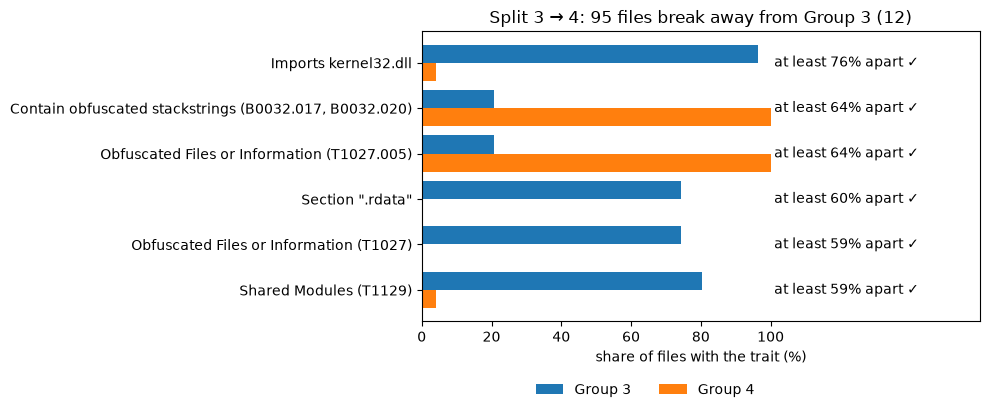

**Split 3 → 4: 95 files break away from Group 3 (12)**

- **Imports kernel32.dll**: 96% of Group 3 vs 4% of Group 4
- **Contain obfuscated stackstrings (B0032.017, B0032.020)**: 100% of Group 4 vs 21% of Group 3
- Families: Group 3: zeus 63, jeefo 52, disco 51 (of 983); Group 4: trickbot 95 (of 95)

<details><summary>Details</summary>

- **Lineage:** Group 3 (12) → Group 3 (121) + Group 4 (122)
- **Strongest traits.** Share of files with the trait in each part, then the *cautious difference*: how far apart the two shares are at least, according to Newcombe's interval with the Bonferroni correction. A split is explained when it is at least τ = 0.30.
  - Imports kernel32.dll: 96% of Group 3 vs 4% of Group 4; cautious difference 76%
  - Contain obfuscated stackstrings (B0032.017, B0032.020): 21% of Group 3 vs 100% of Group 4; cautious difference 64%
  - Obfuscated Files or Information (T1027.005): 21% of Group 3 vs 100% of Group 4; cautious difference 64%
- **Family separation** 1.00: total variation distance between the families of the two parts (1 = no family in common). Used only to check the method, never to explain.
- **Coverage** 100%: the share of the files that change between 3 and 4 groups that this split describes. **Cleanliness** 1.000: the share of files that stay in their group's line of descent (1 = one clean split).

</details>

In [14]:
# Runs the whole analysis with Ward, then draws one explained split: each trait's share in the two
# parts, and its cautious difference.

results = {"ward": analyse(df, "ward")}
ward = results["ward"]["rows"]
example = next((r for r in ward if r["explained"] and r["k_from"] > 1), ward[0])


def example_chart(r, n=6):
    a, b = r["_a"], r["_b"]
    pa, pb = Rm[a].mean(axis=0), Rm[b].mean(axis=0)
    bound = conservative_difference(pa, a.sum(), pb, b.sum(), results["ward"]["z"])
    order = np.argsort(-bound, kind="stable")[:n][::-1]
    fig, ax = plt.subplots(figsize=(10, 0.55 * n + 1))
    y = np.arange(len(order))
    ax.barh(y + 0.2, pa[order] * 100, 0.4, label=short(r["_label_a"]), color="tab:blue")
    ax.barh(y - 0.2, pb[order] * 100, 0.4, label=short(r["_label_b"]), color="tab:orange")
    for yi, i in zip(y, order):
        ok = bound[i] >= MIN_CONTRAST
        ax.text(101, yi, f"at least {bound[i]:.0%} apart" + (" ✓" if ok else ""), va="center",
                color="black" if ok else "gray")
    ax.set_yticks(y, [labels[i] if len(labels[i]) < 60 else labels[i][:57] + "…" for i in order])
    ax.set_xlim(0, 160)
    ax.set_xticks(range(0, 101, 20))
    ax.set_xlabel("share of files with the trait (%)")
    ax.set_title(headline(r))
    ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.12 - 0.3 / n), ncol=2, frameon=False)
    plt.tight_layout()
    plt.show()


example_chart(example)
display(Markdown(split_block(example)))

### Which splits are explained

The largest cautious difference of each split; green splits are explained.

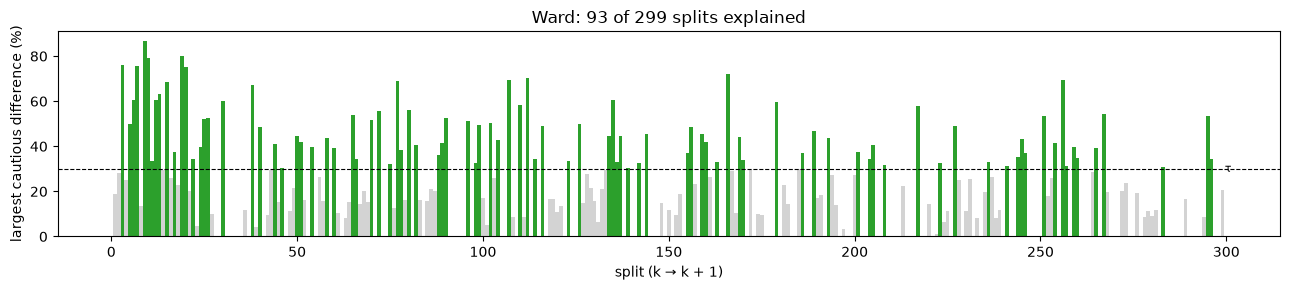

Every split is explained down to 300 groups.

In [15]:
# Draws every split's largest cautious difference, the threshold τ, and where the explanations stop.

def profile_chart(rows, title, ax=None, dry=None):
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(13, 3))
    x = [r["k_from"] for r in rows]
    ax.bar(x, [r["best"] * 100 for r in rows], color=["tab:green" if r["explained"] else "lightgray" for r in rows],
           width=0.9 if len(x) <= 60 else 1.0)
    ax.axhline(MIN_CONTRAST * 100, color="black", lw=0.8, ls="--")
    ax.text(x[-1] + 0.6, MIN_CONTRAST * 100, "τ", va="center", fontsize=8)
    if dry:
        ax.axvline(dry - 0.5, color="tab:red", lw=1, ls="--")
        ax.text(dry - 0.5, ax.get_ylim()[1] * 0.95, f" explanations stop: {dry - 1}→{dry}", color="tab:red", fontsize=8, va="top")
    if len(x) <= 40:
        ax.set_xticks(x, [f"{k}→{k + 1}" for k in x], rotation=90, fontsize=7)
    else:
        ax.set_xlabel("split (k → k + 1)")
    ax.set_ylabel("largest cautious difference (%)")
    ax.set_title(title)
    if show:
        plt.tight_layout()
        plt.show()


profile_chart(ward, f"Ward: {sum(r['explained'] for r in ward)} of {len(ward)} splits explained", dry=results["ward"]["dry_up"])
display(Markdown(depth_sentence(results["ward"])))

### The first splits (Table 2)

The top of Ward's tree, green where a split is explained.

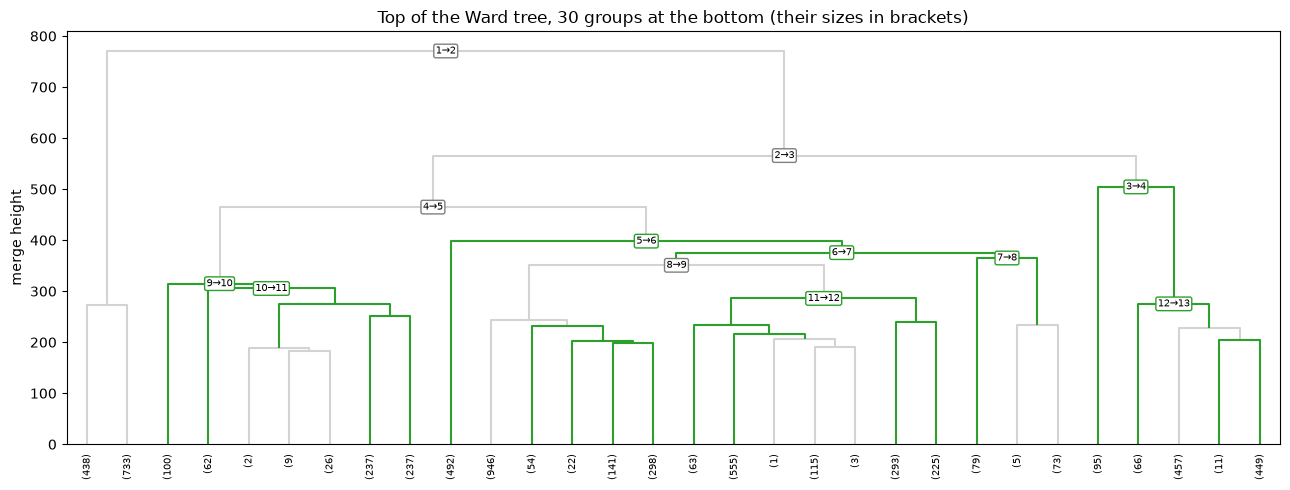

,what happens,main reason
split,,
1→2,1171 files break away from Group 1 (all),not explained
2→3,1078 files break away from Group 1 (1),not explained
3→4,95 files break away from Group 3 (12),Imports kernel32.dll (96% vs 4%)
4→5,673 files break away from Group 1 (11),not explained
5→6,492 files break away from Group 1 (111),Packed: capa couldn't analyse its code (T1027.002) (79% vs 21%)
6→7,157 files break away from Group 1 (1111),Imports msvcrt.dll (96% vs 24%)
7→8,Group 7 (11112) divides in two (79 and 78 files),Imports mfc42.dll (99% vs 0%)
8→9,Group 1 (11111) divides in two (1461 and 1255 files),not explained
9→10,100 files break away from Group 5 (112),Check mutex and terminate process on windows (100% vs 0%)


In [16]:
# Draws the top of Ward's tree, green where a split is explained, and lists the first splits.

def tree_chart(Z, rows, label_first=12):
    n = len(Z) + 1
    by_height = {round(float(Z[n - 1 - r["k_from"], 2]), 9): r for r in rows}

    def colour(link):
        r = by_height.get(round(float(Z[link - n, 2]), 9))
        return "tab:green" if r and r["explained"] else "lightgray"

    def leaf_label(i):        # the size of each group at SHOW_K groups
        return f"({int(Z[i - n, 3]) if i >= n else 1})"

    fig, ax = plt.subplots(figsize=(13, 5))
    d = dendrogram(Z, truncate_mode="lastp", p=SHOW_K, link_color_func=colour, ax=ax,
                   leaf_label_func=leaf_label, leaf_rotation=90, leaf_font_size=7)
    for xs, ys in zip(d["icoord"], d["dcoord"]):
        r = by_height.get(round(ys[1], 9))
        if r and r["k_from"] <= label_first:
            ax.annotate(f"{r['k_from']}→{r['k_to']}", (sum(xs[1:3]) / 2, ys[1]), ha="center", va="center", fontsize=7,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="tab:green" if r["explained"] else "gray"))
    ax.set_ylabel("merge height")
    ax.set_title(f"Top of the Ward tree, {SHOW_K} groups at the bottom (their sizes in brackets)")
    plt.tight_layout()
    plt.show()
    return pd.DataFrame([{"split": f"{r['k_from']}→{r['k_to']}",
                          "what happens": headline(r).split(": ", 1)[1],
                          "main reason": (f"{r['reasons'][0][0]} ({max(r['reasons'][0][1:3]):.0%} vs {min(r['reasons'][0][1:3]):.0%})"
                                          if r["reasons"] else "not explained")}
                         for r in rows[:label_first]]).set_index("split")


tree_chart(Z, ward)

In [17]:
# Validation only: family separation (total variation distance) of explained and unexplained splits.

def separation(rows):
    e = np.array([r["explained"] for r in rows])
    tvd = np.array([r["family_tvd"] for r in rows])
    return (tvd[e].mean() if e.any() else np.nan), (tvd[~e].mean() if (~e).any() else np.nan)


def two(v):
    return "—" if np.isnan(v) else f"{v:.2f}"


te, tu = separation(ward)
print(f"Family separation (total variation distance between the families of the two parts; 1 = no family "
      f"in common): {two(te)} for explained splits vs {two(tu)} for unexplained ones.")

Family separation (total variation distance between the families of the two parts; 1 = no family in common): 0.91 for explained splits vs 0.65 for unexplained ones.


### The first splits, in detail

In [18]:
# Shows the first splits as an analyst would read them.

display(Markdown("\n\n".join(split_block(r) for r in ward[:NARRATIVE_CHANGES])))

**Split 1 → 2: 1171 files break away from Group 1 (all)**

- *No readable trait clearly separates them.* Closest: **Reference anti-vm strings targeting xen**: 25% of Group 2 vs 2% of Group 1.
- Families: Group 1: berbew 100, aenjaris 100, triusor 100 (of 5116); Group 2: virlock 87, neoreklami 86, installmonster 64 (of 1171)

<details><summary>Details</summary>

- **Lineage:** Group 1 (all) → Group 1 (1) + Group 2 (2)
- **Strongest traits.** Share of files with the trait in each part, then the *cautious difference*: how far apart the two shares are at least, according to Newcombe's interval with the Bonferroni correction. A split is explained when it is at least τ = 0.30.
  - none reaches τ = 0.30; the largest cautious difference is 0.19
- **Family separation** 0.73: total variation distance between the families of the two parts (1 = no family in common). Used only to check the method, never to explain.
- **Coverage** 100%: the share of the files that change between 1 and 2 groups that this split describes. **Cleanliness** 1.000: the share of files that stay in their group's line of descent (1 = one clean split).

</details>

**Split 2 → 3: 1078 files break away from Group 1 (1)**

- *No readable trait clearly separates them.* Closest: **Link function at runtime on windows**: 70% of Group 3 vs 36% of Group 1.
- Families: Group 1: stormattack 100, blihan 100, lolbot 100 (of 4038); Group 3: trickbot 95, zeus 63, jeefo 52 (of 1078)

<details><summary>Details</summary>

- **Lineage:** Group 1 (1) → Group 1 (11) + Group 3 (12)
- **Strongest traits.** Share of files with the trait in each part, then the *cautious difference*: how far apart the two shares are at least, according to Newcombe's interval with the Bonferroni correction. A split is explained when it is at least τ = 0.30.
  - none reaches τ = 0.30; the largest cautious difference is 0.28
- **Family separation** 0.71: total variation distance between the families of the two parts (1 = no family in common). Used only to check the method, never to explain.
- **Coverage** 100%: the share of the files that change between 2 and 3 groups that this split describes. **Cleanliness** 1.000: the share of files that stay in their group's line of descent (1 = one clean split).

</details>

**Split 3 → 4: 95 files break away from Group 3 (12)**

- **Imports kernel32.dll**: 96% of Group 3 vs 4% of Group 4
- **Contain obfuscated stackstrings (B0032.017, B0032.020)**: 100% of Group 4 vs 21% of Group 3
- Families: Group 3: zeus 63, jeefo 52, disco 51 (of 983); Group 4: trickbot 95 (of 95)

<details><summary>Details</summary>

- **Lineage:** Group 3 (12) → Group 3 (121) + Group 4 (122)
- **Strongest traits.** Share of files with the trait in each part, then the *cautious difference*: how far apart the two shares are at least, according to Newcombe's interval with the Bonferroni correction. A split is explained when it is at least τ = 0.30.
  - Imports kernel32.dll: 96% of Group 3 vs 4% of Group 4; cautious difference 76%
  - Contain obfuscated stackstrings (B0032.017, B0032.020): 21% of Group 3 vs 100% of Group 4; cautious difference 64%
  - Obfuscated Files or Information (T1027.005): 21% of Group 3 vs 100% of Group 4; cautious difference 64%
- **Family separation** 1.00: total variation distance between the families of the two parts (1 = no family in common). Used only to check the method, never to explain.
- **Coverage** 100%: the share of the files that change between 3 and 4 groups that this split describes. **Cleanliness** 1.000: the share of files that stay in their group's line of descent (1 = one clean split).

</details>

**Split 4 → 5: 673 files break away from Group 1 (11)**

- *No readable trait clearly separates them.* Closest: **Imports user32.dll**: 70% of Group 1 vs 37% of Group 5.
- Families: Group 1: aenjaris 99, mydoom 98, swisyn 97 (of 3365); Group 5: blihan 100, upatre 80, packz 63 (of 673)

<details><summary>Details</summary>

- **Lineage:** Group 1 (11) → Group 1 (111) + Group 5 (112)
- **Strongest traits.** Share of files with the trait in each part, then the *cautious difference*: how far apart the two shares are at least, according to Newcombe's interval with the Bonferroni correction. A split is explained when it is at least τ = 0.30.
  - none reaches τ = 0.30; the largest cautious difference is 0.25
- **Family separation** 0.89: total variation distance between the families of the two parts (1 = no family in common). Used only to check the method, never to explain.
- **Coverage** 100%: the share of the files that change between 4 and 5 groups that this split describes. **Cleanliness** 1.000: the share of files that stay in their group's line of descent (1 = one clean split).

</details>

**Split 5 → 6: 492 files break away from Group 1 (111)**

- **Packed: capa couldn't analyse its code (T1027.002)**: 79% of Group 6 vs 21% of Group 1
- **Section ".rdata"**: 62% of Group 1 vs 14% of Group 6
- Families: Group 1: aenjaris 99, nitol 95, lolbot 94 (of 2873); Group 6: picsys 54, qqrob 51, soltern 45 (of 492)

<details><summary>Details</summary>

- **Lineage:** Group 1 (111) → Group 1 (1111) + Group 6 (1112)
- **Strongest traits.** Share of files with the trait in each part, then the *cautious difference*: how far apart the two shares are at least, according to Newcombe's interval with the Bonferroni correction. A split is explained when it is at least τ = 0.30.
  - Packed: capa couldn't analyse its code (T1027.002): 21% of Group 1 vs 79% of Group 6; cautious difference 50%
  - Section ".rdata": 62% of Group 1 vs 14% of Group 6; cautious difference 40%
  - Shared Modules (T1129): 59% of Group 1 vs 12% of Group 6; cautious difference 40%
- **Family separation** 0.67: total variation distance between the families of the two parts (1 = no family in common). Used only to check the method, never to explain.
- **Coverage** 100%: the share of the files that change between 5 and 6 groups that this split describes. **Cleanliness** 1.000: the share of files that stay in their group's line of descent (1 = one clean split).

</details>

**Split 6 → 7: 157 files break away from Group 1 (1111)**

- **Imports msvcrt.dll**: 96% of Group 7 vs 24% of Group 1
- **Packed with upx (F0001.008)**: 83% of Group 7 vs 11% of Group 1
- Families: Group 1: aenjaris 99, nitol 95, lolbot 94 (of 2716); Group 7: cosmu 78, dinwod 73, lummastealer 5 (of 157)

<details><summary>Details</summary>

- **Lineage:** Group 1 (1111) → Group 1 (11111) + Group 7 (11112)
- **Strongest traits.** Share of files with the trait in each part, then the *cautious difference*: how far apart the two shares are at least, according to Newcombe's interval with the Bonferroni correction. A split is explained when it is at least τ = 0.30.
  - Imports msvcrt.dll: 24% of Group 1 vs 96% of Group 7; cautious difference 60%
  - Packed with upx (F0001.008): 11% of Group 1 vs 83% of Group 7; cautious difference 58%
  - Section "upx0": 11% of Group 1 vs 80% of Group 7; cautious difference 54%
- **Family separation** 0.96: total variation distance between the families of the two parts (1 = no family in common). Used only to check the method, never to explain.
- **Coverage** 100%: the share of the files that change between 6 and 7 groups that this split describes. **Cleanliness** 1.000: the share of files that stay in their group's line of descent (1 = one clean split).

</details>

**Split 7 → 8: Group 7 (11112) divides in two (79 and 78 files)**

- **Imports mfc42.dll**: 99% of Group 7 vs 0% of Group 8
- **Resolve function by parsing pe exports**: 99% of Group 8 vs 0% of Group 7
- Families: Group 7: cosmu 78, shodi 1 (of 79); Group 8: dinwod 73, lummastealer 5 (of 78)

<details><summary>Details</summary>

- **Lineage:** Group 7 (11112) → Group 7 (111121) + Group 8 (111122)
- **Strongest traits.** Share of files with the trait in each part, then the *cautious difference*: how far apart the two shares are at least, according to Newcombe's interval with the Bonferroni correction. A split is explained when it is at least τ = 0.30.
  - Imports mfc42.dll: 99% of Group 7 vs 0% of Group 8; cautious difference 75%
  - Resolve function by parsing pe exports: 0% of Group 7 vs 99% of Group 8; cautious difference 75%
  - AV label: dropper: 0% of Group 7 vs 94% of Group 8; cautious difference 69%
- **Family separation** 1.00: total variation distance between the families of the two parts (1 = no family in common). Used only to check the method, never to explain.
- **Coverage** 100%: the share of the files that change between 7 and 8 groups that this split describes. **Cleanliness** 1.000: the share of files that stay in their group's line of descent (1 = one clean split).

</details>

**Split 8 → 9: Group 1 (11111) divides in two (1461 and 1255 files)**

- *No readable trait clearly separates them.* Closest: **Extract resource via kernel32 functions**: 28% of Group 9 vs 9% of Group 1.
- Families: Group 1: aenjaris 99, triusor 85, lolbot 77 (of 1461); Group 9: nitol 82, juched 77, expiro 73 (of 1255)

<details><summary>Details</summary>

- **Lineage:** Group 1 (11111) → Group 1 (111111) + Group 9 (111112)
- **Strongest traits.** Share of files with the trait in each part, then the *cautious difference*: how far apart the two shares are at least, according to Newcombe's interval with the Bonferroni correction. A split is explained when it is at least τ = 0.30.
  - none reaches τ = 0.30; the largest cautious difference is 0.14
- **Family separation** 0.70: total variation distance between the families of the two parts (1 = no family in common). Used only to check the method, never to explain.
- **Coverage** 100%: the share of the files that change between 8 and 9 groups that this split describes. **Cleanliness** 1.000: the share of files that stay in their group's line of descent (1 = one clean split).

</details>

**Split 9 → 10: 100 files break away from Group 5 (112)**

- **Check mutex and terminate process on windows**: 100% of Group 10 vs 0% of Group 5
- **Create http request**: 100% of Group 10 vs 6% of Group 5
- Families: Group 5: upatre 80, packz 63, stormattack 57 (of 573); Group 10: blihan 100 (of 100)

<details><summary>Details</summary>

- **Lineage:** Group 5 (112) → Group 5 (1121) + Group 10 (1122)
- **Strongest traits.** Share of files with the trait in each part, then the *cautious difference*: how far apart the two shares are at least, according to Newcombe's interval with the Bonferroni correction. A split is explained when it is at least τ = 0.30.
  - Check mutex and terminate process on windows: 0% of Group 5 vs 100% of Group 10; cautious difference 87%
  - Connect to url (C0002.004): 0% of Group 5 vs 100% of Group 10; cautious difference 87%
  - Persist via run registry key (F0012): 0% of Group 5 vs 100% of Group 10; cautious difference 86%
- **Family separation** 1.00: total variation distance between the families of the two parts (1 = no family in common). Used only to check the method, never to explain.
- **Coverage** 100%: the share of the files that change between 9 and 10 groups that this split describes. **Cleanliness** 1.000: the share of files that stay in their group's line of descent (1 = one clean split).

</details>

**Split 10 → 11: 62 files break away from Group 5 (1121)**

- **Imports oleaut32.dll**: 100% of Group 11 vs 1% of Group 5
- **AV label: packed with upx**: 100% of Group 11 vs 9% of Group 5
- Families: Group 5: upatre 80, stormattack 57, vilsel 54 (of 511); Group 11: packz 62 (of 62)

<details><summary>Details</summary>

- **Lineage:** Group 5 (1121) → Group 5 (11211) + Group 11 (11212)
- **Strongest traits.** Share of files with the trait in each part, then the *cautious difference*: how far apart the two shares are at least, according to Newcombe's interval with the Bonferroni correction. A split is explained when it is at least τ = 0.30.
  - Imports oleaut32.dll: 1% of Group 5 vs 100% of Group 11; cautious difference 79%
  - Section "upx2": 2% of Group 5 vs 100% of Group 11; cautious difference 78%
  - AV label: packed with upx: 9% of Group 5 vs 100% of Group 11; cautious difference 71%
- **Family separation** 1.00: total variation distance between the families of the two parts (1 = no family in common). Used only to check the method, never to explain.
- **Coverage** 100%: the share of the files that change between 10 and 11 groups that this split describes. **Cleanliness** 1.000: the share of files that stay in their group's line of descent (1 = one clean split).

</details>

## Other clustering methods (Table 3)

Bisecting k-means also splits one group at a time. k-means re-clusters for each k, so an explanation covers only part of the samples that move (coverage).

In [19]:
# Runs the same analysis with k-means and bisecting k-means, and compares the methods in one table.

for method in METHODS:
    if method not in results:
        t0 = time.time()
        results[method] = analyse(df, method, KMEANS_DEPTH if method == "kmeans" else None)
        print(f"{method}: {time.time() - t0:.0f} s")

summary = {}
for method, res in results.items():
    rows = res["rows"]
    te, tu = separation(rows)
    summary[method] = {"splits explained": f"{sum(r['explained'] for r in rows)} of {len(rows)}",
                       "mean coverage": f"{np.mean([r['coverage'] for r in rows]):.0%}",
                       "family separation (explained vs unexplained)": f"{two(te)} vs {two(tu)}",
                       "ARI at 30 groups": f"{adjusted_rand_score(res['fam'], res['parts'][30]):.2f}"}
    if DEPTH is None:
        summary[method]["explanations stop at"] = (f"{res['dry_up'] - 1}→{res['dry_up']}" if res["dry_up"]
                                                   else f"not by {res['depth']} groups")
pd.DataFrame(summary).T

kmeans: 18 s


bisecting: 156 s


,splits explained,mean coverage,family separation (explained vs unexplained),ARI at 30 groups
ward,93 of 299,100%,0.91 vs 0.65,0.11
kmeans,12 of 29,26%,0.84 vs 0.69,0.10
bisecting,70 of 299,100%,0.90 vs 0.73,0.11


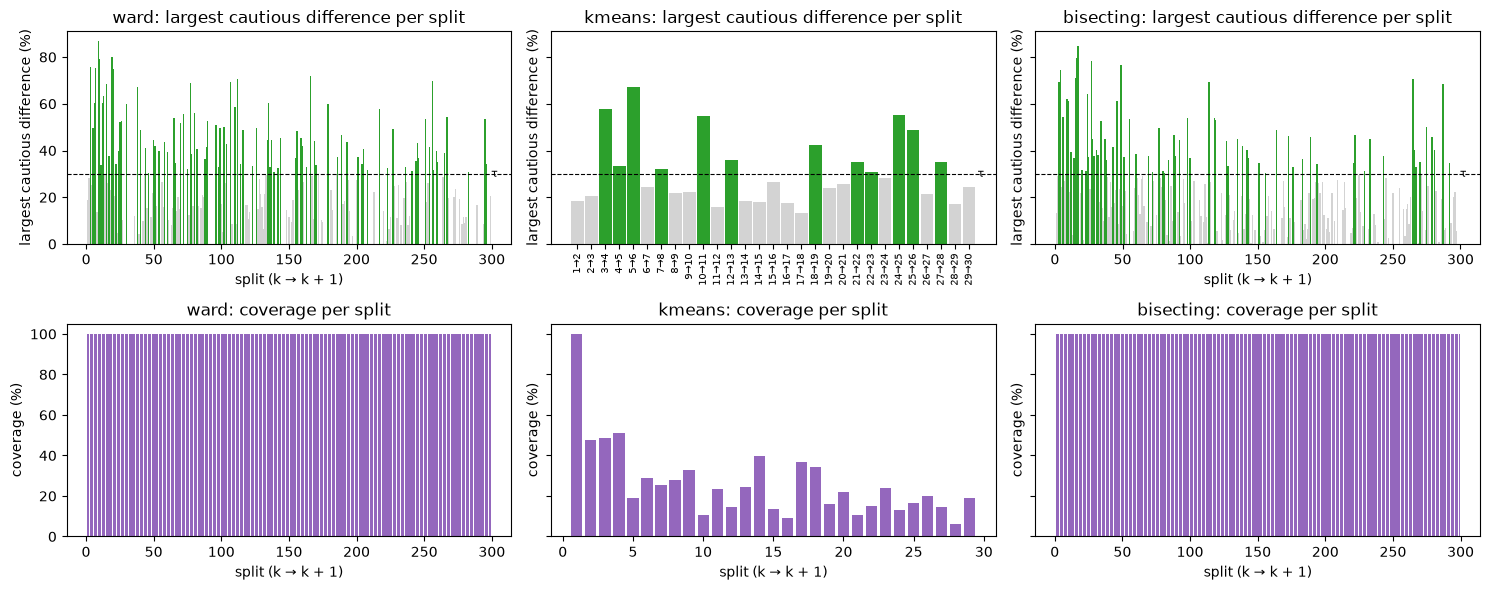

In [20]:
# For each method: the largest cautious difference per split, and the coverage per split.

fig, axes = plt.subplots(2, len(results), figsize=(5 * len(results), 6), sharey="row")
for col, (method, res) in enumerate(results.items()):
    rows = res["rows"]
    profile_chart(rows, f"{method}: largest cautious difference per split", ax=axes[0, col], dry=res["dry_up"])
    axes[1, col].bar([r["k_from"] for r in rows], [r["coverage"] * 100 for r in rows], color="tab:purple")
    axes[1, col].set_ylim(0, 105)
    axes[1, col].set_title(f"{method}: coverage per split")
    axes[1, col].set_ylabel("coverage (%)")
    axes[1, col].set_xlabel("split (k → k + 1)")
plt.tight_layout()
plt.show()

## Packed files: can we trust capa's reasons?

In a packed file capa mostly sees the unpacking code, so a capa reason may reflect packing rather than what the files do. For explained splits whose parts differ in packed share by at least 30 points, capa-only reasons are re-tested on the unpacked files alone; a split is flagged only if none of its reasons holds.

In [21]:
# Which files are packed, and a re-test of capa's reasons on the unpacked files only (Ward).

PACKED_GAP = 0.30                # parts whose share of packed files differs by at least this much
CAPA_KINDS = ("capability", "behaviour", "ATT&CK")
PACKER_LIMITATION = "capability: (internal) packer file limitation"


# Which files are packed: capa's packer limitation, an antivirus packer label or a UPX section.
def packed_flags(df):
    has = lambda items, test: items is not None and any(test(x) for x in items)
    return np.array([has(c, lambda x: x == PACKER_LIMITATION.split(": ", 1)[1]) or has(p, lambda x: True)
                     or has(s, lambda x: x.strip().lower().startswith("upx"))
                     for c, p, s in zip(df["capa"], df["packer_tags"], df["section_names"])])


# capa's own packing detections, reliable even in packed files.
def packing_signal(name):
    return (name == PACKER_LIMITATION or name.startswith("capability: Packed with")
            or name.startswith("behaviour: ANTI-STATIC ANALYSIS: Software Packing"))


# Which merged traits come only from capa (and so may be hidden in packed files).
def capa_only(members):
    return np.array([all(m.split(": ", 1)[0] in CAPA_KINDS for m in group) and not any(map(packing_signal, group))
                     for group in members])


# Re-tests capa-only reasons on the unpacked files when the two parts differ in packing.
def packing_check(Rm, labels, only_capa, packed, a, b, z):
    pa, pb = Rm[a].mean(axis=0), Rm[b].mean(axis=0)
    passing = np.flatnonzero(conservative_difference(pa, a.sum(), pb, b.sum(), z) >= MIN_CONTRAST)
    share_a, share_b = float(packed[a].mean()), float(packed[b].mean())
    gap = abs(share_a - share_b) >= PACKED_GAP
    au, bu = a & ~packed, b & ~packed
    status = {}
    if gap and au.sum() and bu.sum():
        bound_u = conservative_difference(Rm[au].mean(axis=0), au.sum(), Rm[bu].mean(axis=0), bu.sum(), z)
    for i in passing:
        if not only_capa[i]:
            status[labels[i]] = "structural"
        elif not gap:
            status[labels[i]] = "no gap"
        else:
            status[labels[i]] = "holds" if au.sum() and bu.sum() and bound_u[i] >= MIN_CONTRAST else "caveat"
    robust = not len(passing) or any(s != "caveat" for s in status.values())
    return {"packed_a": share_a, "packed_b": share_b, "gap": gap, "status": status, "robust": robust}


packed, only_capa = packed_flags(df), capa_only(members)
explained = [r for r in ward if r["explained"]]
checked = [(r, packing_check(Rm, labels, only_capa, packed, r["_a"], r["_b"], results["ward"]["z"])) for r in explained]
gap = [(r, p) for r, p in checked if p["gap"]]
weak = [f"{r['k_from']}→{r['k_to']}" for r, p in gap if not p["robust"]]
print(f"{packed.mean():.0%} of the files are packed. {len(gap)} of the {len(explained)} explained Ward splits have "
      f"parts that differ in packing; there, capa's reasons were re-tested on the unpacked files only. "
      f"{len(weak)} {'split is' if len(weak) == 1 else 'splits are'} left with no reason that holds"
      + (f" ({', '.join(weak)})." if weak else "."))
pd.DataFrame([{"split": f"{r['k_from']}→{r['k_to']}",
               "packed files (larger vs smaller part)": f"{p['packed_a']:.0%} vs {p['packed_b']:.0%}",
               "capa reasons that hold": sum(s == "holds" for s in p["status"].values()),
               "capa reasons possibly due to packing": sum(s == "caveat" for s in p["status"].values()),
               "structural reasons": sum(s == "structural" for s in p["status"].values()),
               "verdict": "explanation stands" if p["robust"] else "⚠ may reflect packing"}
              for r, p in gap]).set_index("split")

30% of the files are packed. 40 of the 93 explained Ward splits have parts that differ in packing; there, capa's reasons were re-tested on the unpacked files only. 5 splits are left with no reason that holds (51→52, 163→164, 241→242, 251→252, 283→284).


,packed files (larger vs smaller part),capa reasons that hold,capa reasons possibly due to packing,structural reasons,verdict
split,,,,,
5→6,28% vs 80%,0,4,7,explanation stands
6→7,24% vs 84%,0,2,9,explanation stands
9→10,32% vs 0%,32,0,5,explanation stands
10→11,24% vs 100%,0,2,14,explanation stands
17→18,13% vs 49%,2,1,0,explanation stands
19→20,15% vs 76%,15,8,14,explanation stands
20→21,32% vs 0%,13,0,4,explanation stands
25→26,34% vs 0%,44,9,6,explanation stands
26→27,46% vs 9%,3,0,5,explanation stands


## Explore k yourself

Pick a number of groups and a method: you see the split undone by going to k − 1 groups and the one made by going to k + 1.

In [22]:
# An explorer: pick a number of groups and see the split you would undo by removing one group, and
# the one you would make by adding one.

def show_k(k, method="ward"):
    rows = {r["k_from"]: r for r in results[method]["rows"]}
    out = [f"### {method}, {k} groups"]
    if k - 1 in rows:
        out += ["**With one group fewer, this split would be undone:**", split_block(rows[k - 1], details=False)]
    if k in rows:
        out += ["**With one group more, this split would happen:**", split_block(rows[k], details=False)]
    display(Markdown("\n\n".join(out)))


try:
    import ipywidgets as widgets
    deepest = max(len(res["rows"]) for res in results.values())
    widgets.interact(show_k, k=widgets.IntSlider(value=10, min=2, max=deepest, description="groups"),
                     method=list(results))
except ImportError:
    show_k(10)

interactive(children=(IntSlider(value=10, description='groups', max=299, min=2), Dropdown(description='method'…

## Changing τ

The same splits with τ from 0.20 to 0.50: a higher τ explains fewer splits, with stronger reasons.

In [23]:
# Counts the explained splits again with τ from 0.20 to 0.50, with the family separation at each.

table = []
for method, res in results.items():
    for threshold in THRESHOLDS:
        s = sensitivity(res["rows"], threshold)
        table.append({"method": method, "τ": f"{threshold:.2f}", "splits explained": s["explained"],
                      "family separation, explained": s["tvd_explained"],
                      "family separation, unexplained": s["tvd_unexplained"]})
pd.DataFrame(table).pivot(index="τ", columns="method").round(2)

splits explained             family separation, explained               \
method        bisecting kmeans ward                    bisecting kmeans  ward   
τ                                                                               
0.20                118     22  126                         0.88   0.77  0.89   
0.25                 93     15  112                         0.88   0.81  0.91   
0.30                 70     12   93                         0.90   0.84  0.91   
0.35                 56      8   71                         0.90   0.89  0.91   
0.40                 40      6   58                         0.91   0.91  0.91   
0.50                 21      4   33                         0.96   0.94  0.95   

       family separation, unexplained               
method                      bisecting kmeans  ward  
τ                                                   
0.20                             0.70   0.71  0.62  
0.25                             0.72   0.69  0.62  
0.30                             0.73   0.69  0.65  
0.35                             0.74   0.70  0.67  
0.40                             0.75   0.71  0.69  
0.50                             0.75   0.72  0.70

## Can the explanations be trusted?

### Shuffle test

Each split's samples are shuffled between its two parts 100 times, keeping the sizes. A shuffled split has nothing to explain, so every explained shuffle is a false explanation.

In [24]:
# The shuffle test: each split's files are shuffled between its two sides and the same test is
# applied.

# Shuffle test: how often a split with nothing to explain is explained.
def false_explanations(Rm, labels, rows, z, shuffles, rng):
    n, best = len(Rm), []
    for r in rows:
        parent, na = np.flatnonzero(r["_parent"]), int(r["_a"].sum())
        for _ in range(shuffles):
            p = rng.permutation(parent)
            a, b = np.zeros(n, bool), np.zeros(n, bool)
            a[p[:na]], b[p[na:]] = True, True
            best.append(explain(Rm, labels, a, b, z)["best"])
    best = np.array(best)
    return {"shuffled": len(best), "false": int((best >= MIN_CONTRAST).sum()), "largest": float(best.max())}

In [25]:
# Runs the shuffle test on every Ward split explained above.

rng = np.random.default_rng(SEED)
ward_rows = ward[:results["ward"]["dry_up"] - 1] if results["ward"]["dry_up"] else ward
check = false_explanations(Rm, labels, ward_rows, results["ward"]["z"], SHUFFLES, rng)
print(f"Ward: {check['false']} of {check['shuffled']} shuffled splits were explained "
      f"(real splits: {sum(r['explained'] for r in ward_rows)} of {len(ward_rows)}). "
      f"The largest cautious difference on a shuffle was {check['largest']:.0%}, against τ = {MIN_CONTRAST:.2f}.")

Ward: 0 of 29900 shuffled splits were explained (real splits: 93 of 299). The largest cautious difference on a shuffle was 13%, against τ = 0.30.


### Raw difference vs cautious difference

The same shuffled splits, explained with the raw difference between the shares instead of the cautious difference. With small parts and hundreds of traits, some raw difference is large just by chance.

In [26]:
# The shuffle test again with the raw difference, Newcombe's interval without the Bonferroni correction,
# and the cautious difference. Same splits, same shuffles.
RULES = {"Raw difference": None,
         "Newcombe's interval without Bonferroni": norm.isf(ALPHA / 2),
         "Cautious difference (used here)": results["ward"]["z"]}


def best_differences(a, b):
    pa, pb = Rm[a].mean(axis=0), Rm[b].mean(axis=0)
    return [np.abs(pa - pb).max() if z is None else conservative_difference(pa, a.sum(), pb, b.sum(), z).max()
            for z in RULES.values()]


rng = np.random.default_rng(SEED)
real = np.array([best_differences(r["_a"], r["_b"]) for r in ward_rows])
shuffled, smaller = [], []
for r in ward_rows:
    parent, na = np.flatnonzero(r["_parent"]), int(r["_a"].sum())
    for _ in range(SHUFFLES):
        p = rng.permutation(parent)
        a, b = np.zeros(len(Rm), bool), np.zeros(len(Rm), bool)
        a[p[:na]], b[p[na:]] = True, True
        shuffled.append(best_differences(a, b))
        smaller.append(min(na, len(parent) - na))
shuffled, smaller = np.array(shuffled), np.array(smaller)

small = smaller < 10                                          # a part with fewer than 10 files
count = lambda x, n: f"{int(x.sum()):,} of {n:,}"
pd.DataFrame({"real splits explained": [count(real[:, i] >= MIN_CONTRAST, len(real)) for i in range(len(RULES))],
              "shuffled splits explained": [count(shuffled[:, i] >= MIN_CONTRAST, len(shuffled))
                                            for i in range(len(RULES))],
              "… with a part under 10 files": [count(shuffled[small, i] >= MIN_CONTRAST, int(small.sum()))
                                               for i in range(len(RULES))]}, index=list(RULES))

,real splits explained,shuffled splits explained,… with a part under 10 files
Raw difference,272 of 299,"11,740 of 29,900","9,267 of 13,100"
Newcombe's interval without Bonferroni,183 of 299,"88 of 29,900","78 of 13,100"
Cautious difference (used here),93 of 299,"0 of 29,900","0 of 13,100"


### Stability

Each part of a split resampled to 80 % of its samples, 20 times: does the split keep its verdict and its main reason?

In [27]:
# The fixed-split stability check: 80 % of each part of a split, drawn many times, with the same
# test.

BORDERLINE = 0.05                # a split whose largest cautious difference is this close to τ


# Fixed-split stability: resample 80 % of each part, same test, same verdict and reason?
def explanation_stability(Rm, labels, rows, z, subsamples, share, rng):
    n, out = len(Rm), []
    for r in rows:
        ia, ib = np.flatnonzero(r["_a"]), np.flatnonzero(r["_b"])
        same_verdict = same_reason = both = 0
        for _ in range(subsamples):
            a, b = np.zeros(n, bool), np.zeros(n, bool)
            a[rng.choice(ia, max(1, int(share * len(ia))), replace=False)] = True
            b[rng.choice(ib, max(1, int(share * len(ib))), replace=False)] = True
            e = explain(Rm, labels, a, b, z)
            explained = e["best"] >= MIN_CONTRAST
            same_verdict += explained == r["explained"]
            if explained and r["explained"]:
                both += 1
                same_reason += r["reasons"][0][0] in {t[0] for t in e["traits"]} | {t[0] for t in e["reasons"]}
        out.append({"explained": r["explained"], "best": r["best"], "same_verdict": same_verdict / subsamples,
                    "same_reason": same_reason / both if both else None})
    return out


# Averages the stability check for explained, unexplained, borderline and clear splits.
def summarise(stab, borderline=BORDERLINE):
    def group(sel):
        reasons = [s["same_reason"] for s in sel if s["same_reason"] is not None]
        return {"splits": len(sel), "same_verdict": float(np.mean([s["same_verdict"] for s in sel])) if sel else None,
                "same_reason": float(np.mean(reasons)) if reasons else None}
    near = lambda s: abs(s["best"] - MIN_CONTRAST) < borderline
    return {"explained": group([s for s in stab if s["explained"]]),
            "unexplained": group([s for s in stab if not s["explained"]]),
            "borderline": group([s for s in stab if near(s)]),
            "clear": group([s for s in stab if not near(s)])}

In [28]:
# Runs the fixed-split stability check on Ward and summarises it for explained, unexplained,
# borderline and clear splits.

stab = summarise(explanation_stability(Rm, labels, ward_rows, results["ward"]["z"], STABILITY_SUBSAMPLES, 0.8, rng))
pd.DataFrame({group: {"splits": s["splits"],
                      "same verdict": "—" if s["same_verdict"] is None else f"{s['same_verdict']:.0%}",
                      "same main reason (explained in both)": "—" if s["same_reason"] is None else f"{s['same_reason']:.0%}"}
              for group, s in stab.items()}).T.rename(index={"borderline": "borderline (within 0.05 of τ)",
                                                              "clear": "clear (further from τ)"})

,splits,same verdict,same main reason (explained in both)
explained,93,82%,96%
unexplained,206,100%,—
borderline (within 0.05 of τ),41,61%,88%
clear (further from τ),258,99%,98%


## Limitations

- The checks rely on EMBER2024's family labels, which are derived from antivirus detections and can be wrong; only labels with a confidence of at least 0.8 are kept.
- Where the explanations stop is a rough marker: small changes to the data can move it.
- k-means re-clusters for each k, so its explanations cover only part of the files that move between k and k + 1 groups.